# Can I fly? Real METAR reports and wind at flight height

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/drone_weather_hluboka_en.ipynb)

**OpenSkyLab · notebook for the lab** [Can I fly? Weather for drones](https://openskylab.space/edu_viz_drone_weather.html) · [česká verze](drone_weather_hluboka_cs.ipynb)

In the lab you decoded example METAR reports, converted the airport wind to the flight site and height and decided with a traffic light. Here you download real METAR reports from Czech airports for the last 24 hours, decode them yourself and compare the result with a model forecast of wind at 80 and 120 m.

**Goal:** decode METAR, compute relative humidity and an estimate of the cloud base, convert the 10 m wind to flight height over different terrain, estimate the return against the wind, and decide about flying over the next 24 hours.

**Data:** METAR and TAF reports from Linz (LOWL, the nearest airport with regular reports; České Budějovice LKCS was not sending METAR reports to the service in October 2026), Prague (LKPR), Brno (LKTB) and Karlovy Vary (LKKV) airports from the NOAA Aviation Weather Center; an hourly forecast from Open-Meteo for Hluboká nad Vltavou. The data change every half hour, so your numbers will differ from the stored notebook.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

> **💻 What the code does:** Optional cell. If you paste the settings copied from the lab and run it, the cells below take the same parameter values and say so for each one. If you leave it empty, the default values are used. It downloads nothing.

In [1]:
#@title Settings from the lab (optional)
#@markdown In the lab, click the Notebook link. The settings are copied; paste them here in place of `{}` (Ctrl+V) and run the cell.
Z_VIZUALU = {}  #@param {type:"raw"}
STEM = "drone_weather"

def z_viz(name, default, mapping=None):
    """Value of a parameter from the lab if the pasted code contains it; otherwise the default value."""
    z = Z_VIZUALU if isinstance(Z_VIZUALU, dict) and Z_VIZUALU.get("osl") == STEM else {}
    if name not in z:
        return default
    v = z[name]
    if mapping is not None:
        if v not in mapping:
            print(f"{name}: value {v!r} from the lab is not in this notebook, keeping {default!r}")
            return default
        v = mapping[v]
    elif isinstance(default, bool):
        v = bool(v)
    elif isinstance(default, int):
        v = int(round(v))
    elif isinstance(default, float):
        v = float(v)
    print(f"{name} = {v!r}  (from the lab)")
    return v

if isinstance(Z_VIZUALU, dict) and Z_VIZUALU and Z_VIZUALU.get("osl") != STEM:
    print(f"The pasted code is from another lab ({Z_VIZUALU.get('osl')}), the notebook does not use it.")

## 1. Setup and real METAR reports

> **💻 What the code does:** Loads the libraries and defines the function `open_meteo`, which queries the Open-Meteo weather service. If the service does not answer or is overloaded, the function retries several times with a growing pause. Nothing is downloaded yet.

In [2]:
import re, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

> **💻 What the code does:** Downloads the real METAR reports of the last 24 hours from aviationweather.gov for the airports in `STATIONS` (and for the airport from the lab, if it is missing) and the latest TAF forecast. It prints a few of the newest reports and the TAF.

In [3]:
STATIONS = "LOWL,LKPR,LKTB,LKKV"          # ◀ parameter: ICAO airport codes
ST_VIZ = z_viz("STATION", "LOWL")                            # airport of the METAR report pasted into the lab
if ST_VIZ not in STATIONS.split(","): STATIONS += "," + ST_VIZ
raw = requests.get("https://aviationweather.gov/api/data/metar", params={"ids": STATIONS, "format": "raw", "hours": 24}, timeout=60).text.strip().splitlines()
taf = requests.get("https://aviationweather.gov/api/data/taf", params={"ids": "LOWL", "format": "raw"}, timeout=60).text.strip()
print(f"{len(raw)} reports; latest:"); print("\n".join(raw[:6])); print("\nTAF Linz:\n" + taf)

181 reports; latest:
METAR LKKV 312000Z VRB02KT 9999 SCT020 OVC027 05/02 Q1028
METAR LKKV 311900Z VRB02KT 9999 SCT026 OVC040 05/02 Q1028
METAR LKKV 311830Z 32003KT 260V360 9999 SCT030 OVC049 05/02 Q1028
METAR LKKV 311800Z 30005KT 9999 OVC048 05/02 Q1028
METAR LKKV 311730Z VRB05KT 9999 SCT027 OVC038 06/02 Q1028
METAR LKKV 311700Z VRB02KT 9999 OVC035 06/02 Q1028

TAF Linz:
TAF LOWL 311715Z 3118/0118 30005KT 9999 FEW020 SCT030 BKN040 TX08/0113Z TN04/0107Z 
  TEMPO 3118/0111 -SHRA 
  PROB40 
  TEMPO 3120/0108 4000 SHRA BKN013 
  TEMPO 0109/0115 09008KT


## 2. Your own decoder

A report has a fixed order of groups: airport, time, wind (direction, speed, gusts G), visibility in metres or CAVOK, weather (RA rain, SN snow, BR mist, FG fog, - light, + heavy), cloud (FEW, SCT, BKN, OVC and height in hundreds of feet), temperature/dew point (M = minus) and QNH pressure. The part after TEMPO, BECMG or NOSIG is a short trend forecast and the decoder skips it.

> **💻 What the code does:** Defines our own METAR decoder based on regular expressions: it extracts the station, time, wind and gusts (converted to m/s), visibility, weather, cloud layers and the lowest BKN/OVC base, temperature and dew point. It decodes all reports, adds relative humidity and the cloud-base estimate 125 m · (T − Td) and shows the first 12 rows of the table.

In [4]:
KT = 0.514444
def decode(m):
    body = re.split(r"\b(TEMPO|BECMG|NOSIG|RMK)\b", m)[0]
    d = {"station": body.split()[1], "time": re.search(r"\b(\d{6})Z\b", body).group(1)}
    w = re.search(r"\b(\d{3}|VRB)(\d{2,3})(?:G(\d{2,3}))?(KT|MPS)\b", body)
    if w:
        f = KT if w.group(4) == "KT" else 1.0
        d["dir"] = w.group(1); d["wind m/s"] = int(w.group(2)) * f; d["gusts m/s"] = int(w.group(3)) * f if w.group(3) else np.nan
    if "CAVOK" in body:
        d["visibility m"] = 10000
    else:
        v = re.search(r"(?<=KT )(\d{4})\b|(?<=MPS )(\d{4})\b|\s(\d{4})\s", body)
        d["visibility m"] = int(next(g for g in v.groups() if g)) if v else np.nan
    d["weather"] = " ".join(re.findall(r"(?<=\s)([-+]?(?:VC)?(?:MI|BC|PR|DR|BL|SH|TS|FZ)?(?:DZ|RA|SN|SG|PL|GR|GS|BR|FG|FU|HZ|SQ)+)(?=\s)", body + " "))
    clouds = re.findall(r"\b(FEW|SCT|BKN|OVC|VV)(\d{3})", body)
    d["cloud"] = " ".join(f"{c}{int(h) * 100}ft" for c, h in clouds)
    ceil = [int(h) * 100 * 0.3048 for c, h in clouds if c in ("BKN", "OVC", "VV")]
    d["BKN/OVC base m"] = min(ceil) if ceil else np.nan
    tt = re.search(r"\b(M?\d{2})/(M?\d{2})\b", body)
    if tt:
        d["T °C"], d["Td °C"] = (int(x.replace("M", "-")) for x in tt.groups())
    return d

met = pd.DataFrame([decode(m) for m in raw])
met["RH %"] = 100 * np.exp(17.62 * met["Td °C"] / (243.12 + met["Td °C"])) / np.exp(17.62 * met["T °C"] / (243.12 + met["T °C"]))
met["estimated base m"] = 125 * (met["T °C"] - met["Td °C"])
met.head(12).round(1)

,station,time,dir,wind m/s,gusts m/s,visibility m,weather,cloud,BKN/OVC base m,T °C,Td °C,RH %,estimated base m
0,LKKV,312000,VRB,1.0,NaN,9999,,SCT2000ft OVC2700ft,823.0,5,2,81.0,375
1,LKKV,311900,VRB,1.0,NaN,9999,,SCT2600ft OVC4000ft,1219.2,5,2,81.0,375
2,LKKV,311830,320,1.5,NaN,9999,,SCT3000ft OVC4900ft,1493.5,5,2,81.0,375
3,LKKV,311800,300,2.6,NaN,9999,,OVC4800ft,1463.0,5,2,81.0,375
4,LKKV,311730,VRB,2.6,NaN,9999,,SCT2700ft OVC3800ft,1158.2,6,2,75.5,500
5,LKKV,311700,VRB,1.0,NaN,9999,,OVC3500ft,1066.8,6,2,75.5,500
6,LKKV,311630,300,1.5,NaN,9999,,SCT2800ft OVC4200ft,1280.2,6,2,75.5,500
7,LKKV,311600,300,2.1,NaN,9999,,OVC3600ft,1097.3,6,2,75.5,500
8,LKKV,311530,350,1.5,NaN,9999,,SCT2600ft BKN3100ft,944.9,7,2,70.5,625
9,LKKV,311500,330,1.5,NaN,9999,,BKN3700ft,1127.8,7,2,70.5,625


> **✏️ Task 1.** Pick one report and decode it by hand group by group; does it agree with the table? Which groups alone would rule out a VLOS flight (visibility, fog, low cloud, precipitation)? Why is the difference T − Td more important to a pilot than the temperature alone?

*Your answer:* 

> **💻 What the code does:** For reports with BKN or OVC cloud it plots the cloud-base estimate 125 m · (T − Td) against the reported base. The dotted line marks a perfect match.

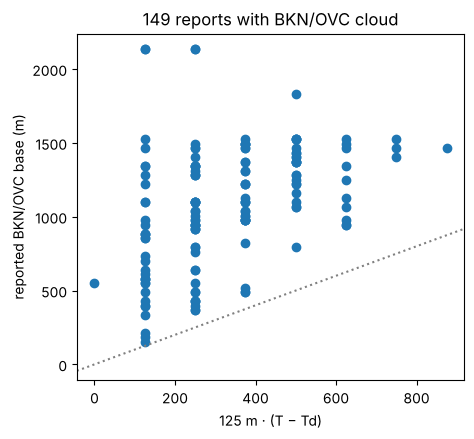

In [5]:
c = met.dropna(subset=["BKN/OVC base m"])
plt.figure(figsize=(5, 4.5))
plt.scatter(c["estimated base m"], c["BKN/OVC base m"])
plt.axline((0, 0), slope=1, color="gray", ls=":")
plt.xlabel("125 m · (T − Td)"); plt.ylabel("reported BKN/OVC base (m)"); plt.title(f"{len(c)} reports with BKN/OVC cloud"); plt.show()

> **✏️ Task 2.** How well does the estimate 125 m · (T − Td) match the reported cloud base? The estimate holds for cumulus in a well-mixed daytime layer. Find reports where it fails and explain why (night, stratiform cloud, inversion, cloud from another air mass).

*Your answer:* 

## 3. Wind at flight height over different terrain

Airports measure wind 10 m above grass (roughness length z0 = 0.03 m). At a blending height of 60 m the surface hardly matters, so we transfer the wind there to the flight site with a different roughness z0 and zero-plane displacement d (Wieringa 1986). This holds for neutral stratification (windy, overcast); on a sunny day or at night the profile differs.

> **💻 What the code does:** With a logarithmic profile it carries the wind measured at the airport at 10 m up to the blending height and from there down over four terrain types with different roughness. The default wind `u10` is the latest METAR from the chosen airport. It plots wind profiles up to 150 m and prints the wind at 30 and 100 m.

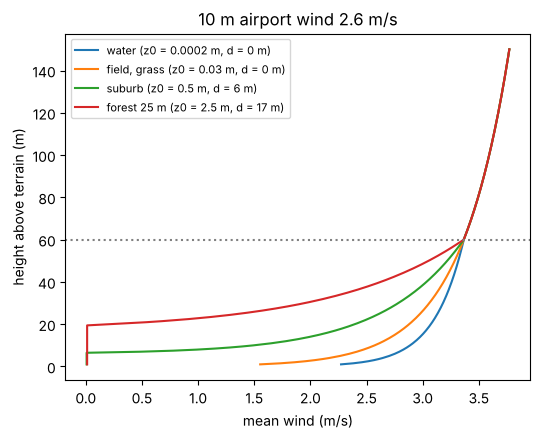

water       : 30 m  3.2 m/s, 100 m  3.6 m/s
field, grass: 30 m  3.1 m/s, 100 m  3.6 m/s
suburb      : 30 m  2.8 m/s, 100 m  3.6 m/s
forest 25 m : 30 m  2.0 m/s, 100 m  3.6 m/s


In [6]:
def wind_at(z, u10, z0=0.03, d=0.0, zb=60.0):
    ub = u10 * np.log(zb / 0.03) / np.log(10 / 0.03)                    # wind at the blending height above the airport
    z = np.asarray(z, float)
    site = ub * np.log(np.maximum(z - d, z0 * 1.01) / z0) / np.log((zb - d) / z0)
    above = ub * np.log(z / 0.03) / np.log(zb / 0.03)
    return np.where(z <= zb, site, above)

TERRAIN = {"water": (0.0002, 0), "field, grass": (0.03, 0), "suburb": (0.5, 6), "forest 25 m": (2.5, 17)}
ST_U = ST_VIZ if (met["station"] == ST_VIZ).any() else "LOWL"
u10 = float(met[met["station"] == ST_U]["wind m/s"].iloc[0])     # ◀ parameter: wind at 10 m (default is the latest Linz METAR)
z = np.linspace(1, 150, 300)
plt.figure(figsize=(6, 4.5))
for name, (z0, d) in TERRAIN.items():
    plt.plot(wind_at(z, u10, z0, d), z, label=f"{name} (z0 = {z0} m, d = {d} m)")
plt.axhline(60, color="gray", ls=":"); plt.xlabel("mean wind (m/s)"); plt.ylabel("height above terrain (m)")
plt.title(f"10 m airport wind {u10:.1f} m/s"); plt.legend(fontsize=8); plt.show()
for name, (z0, d) in TERRAIN.items():
    print(f"{name:12s}: 30 m {wind_at(30, u10, z0, d):4.1f} m/s, 100 m {wind_at(100, u10, z0, d):4.1f} m/s")

> **💻 What the code does:** Downloads a two-day hourly forecast from Open-Meteo for the flight site and computes the ratio of model wind at 80 and 10 m. It prints it next to the ratio from our profile over a field and over suburbs.

In [7]:
fc = open_meteo({"latitude": 49.052, "longitude": 14.439, "forecast_days": 2, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                 "hourly": "wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_gusts_10m,temperature_2m,dew_point_2m,visibility,precipitation"})
fc = pd.DataFrame(fc["hourly"]).set_index("time")
ratio80 = (fc.wind_speed_80m / fc.wind_speed_10m)[fc.wind_speed_10m > 2]
print(f"Open-Meteo for Hluboká: wind ratio 80 m / 10 m median {ratio80.median():.2f} (range {ratio80.min():.2f}–{ratio80.max():.2f})")
print(f"our profile over a field: {wind_at(80, 1.0, 0.03, 0) / 1.0:.2f}, over a suburb: {wind_at(80, 1.0, 0.5, 6) / wind_at(10, 1.0, 0.5, 6):.2f}")

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo for Hluboká: wind ratio 80 m / 10 m median 1.73 (range 1.24–2.08)
our profile over a field: 1.36, over a suburb: 2.34


> **✏️ Task 3.** Why is the mean wind at 30 m weaker over forest than over water, but almost the same at 100 m? A colleague says: "The airport reports 6 m/s, the drone handles 12 m/s, we have a twofold margin." Set `u10 = 6` and answer with numbers for 100 m. How does the 80 m / 10 m ratio from the Open-Meteo model differ from our profile and why (stability during day and night)?

*Your answer:* 

## 4. The way back against the wind

The drone flies at airspeed V, the wind at flight height is U. Over a distance D downwind out and upwind back the flight takes t = D/(V + U) + D/(V − U).

> **💻 What the code does:** Computes the time to fly out with the wind and back against it for drone speed `V` and distance `D` at winds from 0 to 11.5 m/s and plots it. It prints the time without wind and the wind at which the time doubles.

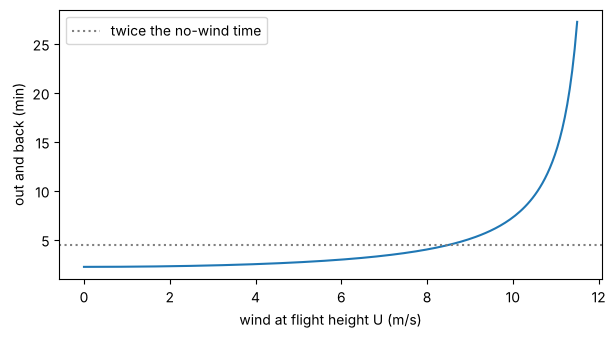

no wind 2.2 min; doubled at U = 8.5 m/s


In [8]:
V, D = 12.0, 800          # ◀ parameter: airspeed (m/s) and distance from the pilot (m)
U = np.linspace(0, 11.5, 200)
t_rt = D / (V + U) + D / (V - U)
plt.figure(figsize=(7, 3.5)); plt.plot(U, t_rt / 60); plt.axhline(2 * D / V / 60 * 2, color="gray", ls=":", label="twice the no-wind time")
plt.xlabel("wind at flight height U (m/s)"); plt.ylabel("out and back (min)"); plt.legend(); plt.show()
print(f"no wind {2 * D / V / 60:.1f} min; doubled at U = {V / np.sqrt(2):.1f} m/s")

> **✏️ Task 4.** Derive from the formula at what wind the round-trip time doubles (the cell prints U = V/√2). Why is it not enough that the mean wind at flight height is below the drone's wind resistance when gusts (the gust column in METAR) are 30–50 % higher? How would you plan the route accordingly?

*Your answer:* 

## 5. A traffic light for the next 48 hours

For each hour of the Open-Meteo forecast for the flight site we decide: wind at 120 m and gusts against the drone's limit, precipitation, visibility and icing risk (temperature below 1 °C and T − Td within 2 °C).

> **💻 What the code does:** For each hour of the forecast from the earlier cell it compares the wind at 120 m and the gust estimate with the drone limit `limit` and checks precipitation, visibility and icing risk. It shows a coloured table with the verdict ok / caution / DO NOT FLY.

In [9]:
limit = 12.0               # ◀ parameter: drone wind resistance (m/s)
gust_factor = (fc.wind_gusts_10m / fc.wind_speed_10m.clip(lower=1)).clip(upper=2.5)
wind_fl = fc.wind_speed_120m
gust_fl = wind_fl * gust_factor
red = (gust_fl > limit) | (fc.precipitation > 0.5) | (fc.visibility < 1000)
icing = (fc.temperature_2m < 1) & (fc.temperature_2m - fc.dew_point_2m <= 2)
yellow = ~red & ((gust_fl > 0.75 * limit) | (fc.precipitation > 0) | (fc.visibility < 5000) | icing)
status = np.where(red, "NO GO", np.where(yellow, "caution", "ok"))
out = pd.DataFrame({"wind 120 m": wind_fl, "gusts ~": gust_fl, "precip. mm": fc.precipitation, "visibility km": fc.visibility / 1000,
                    "T": fc.temperature_2m, "T−Td": fc.temperature_2m - fc.dew_point_2m, "verdict": status}).round(1)
colors = {"ok": "#cfe8cf", "caution": "#ffe7a3", "NO GO": "#f4b6b6"}
out.style.apply(lambda r: [f"background-color: {colors[r['verdict']]}"] * len(r), axis=1)

,wind 120 m,gusts ~,precip. mm,visibility km,T,T−Td,verdict
time,,,,,,,
2026-10-31T00:00,3.700000,9.100000,0.000000,24.400000,6.500000,1.900000,caution
2026-10-31T01:00,1.300000,3.200000,0.000000,21.500000,6.300000,1.500000,ok
2026-10-31T02:00,2.500000,5.500000,0.000000,18.500000,6.100000,1.200000,ok
2026-10-31T03:00,2.500000,4.100000,0.000000,20.400000,6.000000,1.400000,ok
2026-10-31T04:00,2.700000,5.000000,0.000000,17.600000,5.900000,1.200000,ok
2026-10-31T05:00,2.600000,5.000000,0.000000,16.700000,5.800000,1.100000,ok
2026-10-31T06:00,2.500000,5.600000,0.000000,17.300000,5.700000,1.200000,ok
2026-10-31T07:00,3.300000,5.100000,0.000000,15.700000,5.700000,1.000000,ok
2026-10-31T08:00,3.600000,5.800000,0.000000,16.400000,5.700000,1.200000,ok


> **✏️ Task 5.** When would you fly in the next 48 hours and what decides the other hours? Compare the forecast with the latest TAF for Linz: do they agree? We estimated gusts at 120 m from the gust-to-wind ratio at 10 m; why is that rough, and is the result on the safe side or not? Set `limit = 10.7` (wind resistance of a small sub-250 g drone such as the DJI Mini 4 Pro). What changes?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for another site and other airports (Roztoky and Prague; Brno-Bystrc and Brno-Tuřany; Hluboká and Linz). Compare, for the same hour, the METAR wind, the 80 m / 10 m wind ratio from Open-Meteo and the traffic-light result. Why does the ratio differ with site and terrain?

*Your answer:* 

---
### Data sources and references

- METAR and TAF: NOAA/NWS Aviation Weather Center, https://aviationweather.gov/data/api/ (US government public data).
- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Relative humidity and saturation vapour pressure (Magnus formula): WMO (2018). *Guide to Instruments and Methods of Observation* (WMO-No. 8), annex 4.B.
- Wind transfer via a 60 m blending height: Wieringa, J. (1986). Roughness-dependent geographical interpolation of surface wind speed averages. *Quarterly Journal of the Royal Meteorological Society* 112, 867–889; Verkaik, J. W. (2000). Evaluation of two gustiness models for exposure correction calculations. *Journal of Applied Meteorology* 39, 1613–1626.
- METAR code: ICAO Annex 3 / WMO-No. 306, code FM 15.
- DJI Mavic 3 Enterprise wind resistance 12 m/s, max. speed 15 m/s in normal mode, 21 m/s in sport mode (DJI data sheet); DJI Mini 4 Pro wind resistance 10.7 m/s.

### How to cite

OpenSkyLab (2026). Can I fly? Real METAR reports and wind at flight height [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/drone_weather_hluboka_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*